<a href="https://colab.research.google.com/github/ancyjohn-726/Supervised_Learning_Assessment_AncyJohn/blob/main/Supervised_Learning_Assessment_AncyJohn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **SUPERVISED LEARNING – MACHINE TEST**

# 1. Data understanding and exploratory analysis

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [9]:
filepath="/content/bank_marketing_assessment_dataset.csv"
df=pd.read_csv(filepath)
df.head()

,customer_age,job,marital_status,education,account_balance,housing_loan,personal_loan,contact_type,contact_month,campaign_contacts,previous_contacts,engagement_score,annual_income_estimate,subscribed
0,69,retired,divorced,secondary,5467.0,no,no,unknown,nov,4,0,8,23029,no
1,21,admin,single,secondary,606.0,no,no,telephone,may,8,0,1,12000,no
2,27,technician,married,tertiary,-314.0,yes,no,cellular,nov,12,0,10,43597,no
3,53,management,single,secondary,1503.0,yes,yes,cellular,nov,6,0,10,24602,no
4,51,management,single,secondary,3037.0,no,no,unknown,jun,5,0,2,27127,no


In [10]:
df.shape

(600, 14)

In [11]:
df.columns

Index(['customer_age', 'job', 'marital_status', 'education', 'account_balance',
       'housing_loan', 'personal_loan', 'contact_type', 'contact_month',
       'campaign_contacts', 'previous_contacts', 'engagement_score',
       'annual_income_estimate', 'subscribed'],
      dtype='object')

In [12]:
df.dtypes

,0
customer_age,int64
job,object
marital_status,object
education,object
account_balance,float64
housing_loan,object
personal_loan,object
contact_type,object
contact_month,object
campaign_contacts,int64


In [5]:
df.head()

,customer_age,job,marital_status,education,account_balance,housing_loan,personal_loan,contact_type,contact_month,campaign_contacts,previous_contacts,engagement_score,annual_income_estimate,subscribed
0,69,retired,divorced,secondary,5467.0,no,no,unknown,nov,4,0,8,23029,no
1,21,admin,single,secondary,606.0,no,no,telephone,may,8,0,1,12000,no
2,27,technician,married,tertiary,-314.0,yes,no,cellular,nov,12,0,10,43597,no
3,53,management,single,secondary,1503.0,yes,yes,cellular,nov,6,0,10,24602,no
4,51,management,single,secondary,3037.0,no,no,unknown,jun,5,0,2,27127,no


In [6]:
df.isnull().sum()

,0
customer_age,0
job,0
marital_status,0
education,15
account_balance,12
housing_loan,0
personal_loan,0
contact_type,9
contact_month,0
campaign_contacts,0


In [14]:
df.duplicated().sum()

np.int64(0)

In [13]:
# 1. Target Class Distribution

print("Target Class Distribution (Percentage):")
print(df['subscribed'].value_counts(normalize=True) * 100)

Target Class Distribution (Percentage):
subscribed
no     71.0
yes    29.0
Name: proportion, dtype: float64


/tmp/ipykernel_901/112208425.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='subscribed', ax=axes[0], palette='Set2')
/tmp/ipykernel_901/112208425.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='subscribed', y='customer_age', ax=axes[1], palette='Pastel1')


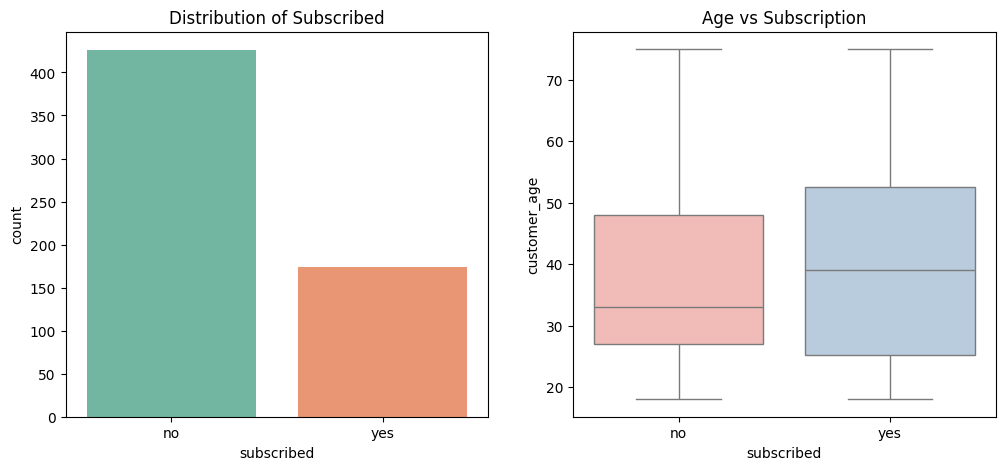

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.countplot(data=df, x='subscribed', ax=axes[0], palette='Set2')
axes[0].set_title('Distribution of Subscribed')
sns.boxplot(data=df, x='subscribed', y='customer_age', ax=axes[1], palette='Pastel1')
axes[1].set_title('Age vs Subscription')
plt.show()

# 2. Data preparation and feature engineering

In [19]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Separate input features (X) and target (y)
X = df.drop(columns=['subscribed'])
y = df['subscribed'].map({'no': 0, 'yes': 1})

In [20]:
# Split data into training and test sets (80:20 split, stratified, random state fixed)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
print(f"Training set shape: {X_train.shape}")
print(f"Test set shape: {X_test.shape}")

Training set shape: (480, 13)
Test set shape: (120, 13)


In [21]:
from sklearn.impute import SimpleImputer
import pandas as pd

# Identify numerical and categorical columns
num_cols = X_train.select_dtypes(include=['number']).columns
cat_cols = X_train.select_dtypes(include=['object']).columns

# Handle numerical missing values (using median)
num_imputer = SimpleImputer(strategy='median')
X_train_num_imputed = pd.DataFrame(num_imputer.fit_transform(X_train[num_cols]), columns=num_cols, index=X_train.index)
X_test_num_imputed = pd.DataFrame(num_imputer.transform(X_test[num_cols]), columns=num_cols, index=X_test.index)

# Handle categorical missing values (using mode)
cat_imputer = SimpleImputer(strategy='most_frequent')
X_train_cat_imputed = pd.DataFrame(cat_imputer.fit_transform(X_train[cat_cols]), columns=cat_cols, index=X_train.index)
X_test_cat_imputed = pd.DataFrame(cat_imputer.transform(X_test[cat_cols]), columns=cat_cols, index=X_test.index)
print("Missing values handled successfully.")

Missing values handled successfully.


In [22]:
from sklearn.preprocessing import StandardScaler

# Fit scaler strictly on imputed training numerical data
scaler = StandardScaler()
X_train_num_scaled = pd.DataFrame(scaler.fit_transform(X_train_num_imputed), columns=num_cols, index=X_train.index)
X_test_num_scaled = pd.DataFrame(scaler.transform(X_test_num_imputed), columns=num_cols, index=X_test.index)
print("Numerical features scaled successfully.")

Numerical features scaled successfully.


In [26]:
from sklearn.preprocessing import OneHotEncoder

# Fit One-Hot Encoder strictly on imputed training categorical data
encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
X_train_cat_encoded_raw = encoder.fit_transform(X_train_cat_imputed)
X_test_cat_encoded_raw = encoder.transform(X_test_cat_imputed)

# Get feature names for mapping back to dataframe
encoded_cols = encoder.get_feature_names_out(cat_cols)
X_train_cat_encoded = pd.DataFrame(X_train_cat_encoded_raw, columns=encoded_cols, index=X_train.index)
X_test_cat_encoded = pd.DataFrame(X_test_cat_encoded_raw, columns=encoded_cols, index=X_test.index)
print("Categorical features encoded successfully.")

Categorical features encoded successfully.


In [27]:
# Combine numerical and categorical datasets together
X_train_final = pd.concat([X_train_num_scaled, X_train_cat_encoded], axis=1)
X_test_final = pd.concat([X_test_num_scaled, X_test_cat_encoded], axis=1)
X_train_preprocessed = X_train_final.values
X_test_preprocessed = X_test_final.values
print(f"Final training shape: {X_train_final.shape}")
print(f"Final test shape: {X_test_final.shape}")

Final training shape: (480, 31)
Final test shape: (120, 31)


In [28]:
# Ensure preprocessing is fitted only on the training data; avoid data leakage
from sklearn.compose import make_column_transformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import make_pipeline

# Group features by type
num_cols = X.select_dtypes(include=['int64', 'float64']).columns
cat_cols = X.select_dtypes(include=['object']).columns

# Create simple pipelines for both feature types
preprocessor = make_column_transformer(
    (make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), num_cols),
    (make_pipeline(SimpleImputer(strategy='most_frequent'), OneHotEncoder(handle_unknown='ignore', sparse_output=False)), cat_cols))

# Fit on training data and transform both to prevent data leakage
X_train_preprocessed = preprocessor.fit_transform(X_train)
X_test_preprocessed = preprocessor.transform(X_test)
print("Preprocessing completed successfully without data leakage.")

Preprocessing completed successfully without data leakage.


# 3. Model building

In [36]:
from sklearn.linear_model import LinearRegression

# Initialize and train the Logistic Regression model
log_reg = LogisticRegression(random_state=42, max_iter=1000)
log_reg.fit(X_train_preprocessed, y_train)
print("Logistic Regression model successfully trained.")

Logistic Regression model successfully trained.


In [37]:
from sklearn.tree import DecisionTreeClassifier

# Initialize and train the Decision Tree Classifier
dt_classifier = DecisionTreeClassifier(random_state=42, max_depth=5)
dt_classifier.fit(X_train_preprocessed, y_train)
print("Decision Tree Classifier successfully trained.")

Decision Tree Classifier successfully trained.


# 4. Model evaluation and comparison

In [38]:
from sklearn.metrics import precision_score, recall_score
from sklearn.metrics import accuracy_score, f1_score

print("Logistic Regression:")
print("Accuracy Score:",accuracy_score(y_test, log_reg.predict(X_test_preprocessed)))
print("Precision Score:",precision_score(y_test, log_reg.predict(X_test_preprocessed)))
print("Recall Score:",recall_score(y_test, log_reg.predict(X_test_preprocessed)))
print("F1 Score",f1_score(y_test, log_reg.predict(X_test_preprocessed)))

Logistic Regression:
Accuracy Score: 0.85
Precision Score: 0.8695652173913043
Recall Score: 0.5714285714285714
F1 Score 0.6896551724137931


In [39]:
print("Decision Tree Classifier:")
print("Accuracy Score:",accuracy_score(y_test, dt_classifier.predict(X_test_preprocessed)))
print("Precision Score:",precision_score(y_test, dt_classifier.predict(X_test_preprocessed)))
print("Recall Score:",recall_score(y_test, dt_classifier.predict(X_test_preprocessed)))
print("F1 Score",f1_score(y_test, dt_classifier.predict(X_test_preprocessed)))

Decision Tree Classifier:
Accuracy Score: 0.8666666666666667
Precision Score: 0.8518518518518519
Recall Score: 0.6571428571428571
F1 Score 0.7419354838709677


=== Confusion Matrix: Logistic Regression ===
True Negatives (TN): 82  | False Positives (FP): 3
False Negatives (FN): 15 | True Positives (TP): 20

=== Confusion Matrix: Decision Tree ===
True Negatives (TN): 81  | False Positives (FP): 4
False Negatives (FN): 12 | True Positives (TP): 23



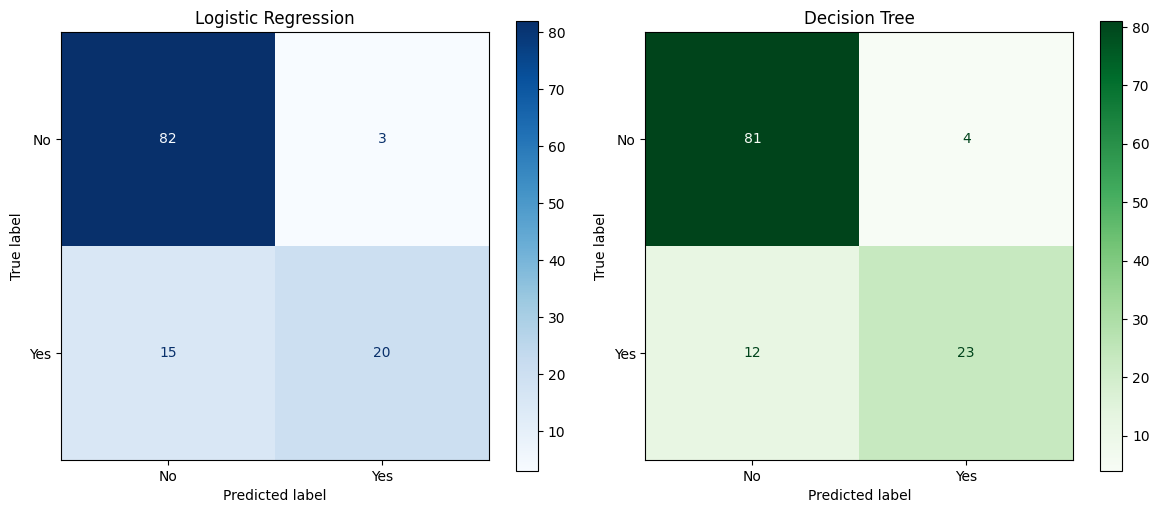

In [43]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Calculate confusion matrices
cm_log_reg = confusion_matrix(y_test, log_reg.predict(X_test_preprocessed))
cm_dt = confusion_matrix(y_test, dt_classifier.predict(X_test_preprocessed))

# Print textual representations
print("=== Confusion Matrix: Logistic Regression ===")
print(f"True Negatives (TN): {cm_log_reg[0, 0]}  | False Positives (FP): {cm_log_reg[0, 1]}")
print(f"False Negatives (FN): {cm_log_reg[1, 0]} | True Positives (TP): {cm_log_reg[1, 1]}\n")

print("=== Confusion Matrix: Decision Tree ===")
print(f"True Negatives (TN): {cm_dt[0, 0]}  | False Positives (FP): {cm_dt[0, 1]}")
print(f"False Negatives (FN): {cm_dt[1, 0]} | True Positives (TP): {cm_dt[1, 1]}\n")

# Plot both confusion matrices side-by-side
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay(confusion_matrix=cm_log_reg, display_labels=['No', 'Yes']).plot(ax=axes[0], cmap='Blues')
axes[0].set_title('Logistic Regression')

ConfusionMatrixDisplay(confusion_matrix=cm_dt, display_labels=['No', 'Yes']).plot(ax=axes[1], cmap='Greens')
axes[1].set_title('Decision Tree')

plt.tight_layout()
plt.show()

### Compare the models and explain which one you would recommend for this business problem. Consider the cost of missing likely subscribers as well as overall performance

Recommendation: The Decision Tree Classifier is recommended.

Higher Recall: The Decision Tree correctly identified 23 out of 35 actual subscribers, whereas Logistic Regression only captured 20. This means using the Decision Tree model avoids missing 3 additional likely subscribers (reducing False Negatives from 15 to 12). Better Overall Balance (F1-Score of 74.19% vs 68.97%): The Decision Tree achieves a significantly better F1-Score while maintaining an overall test accuracy of 86.67%.

# 5. Business interpretation and prediction

/tmp/ipykernel_901/1412146701.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feature_importance_df.head(10), x='Importance', y='Feature', palette='Pastel2')


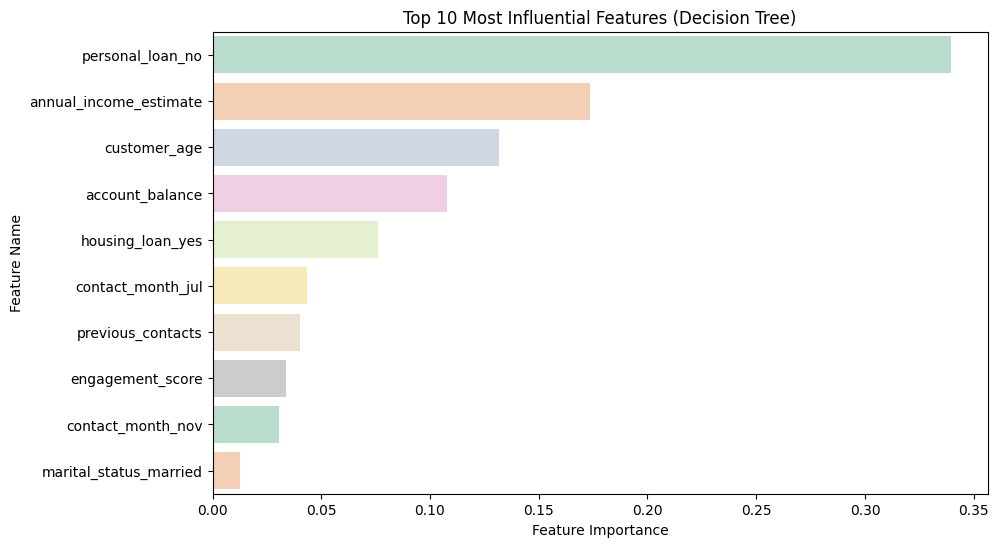

In [47]:
# Extract feature importances
feature_names = num_cols.tolist() + encoded_cols.tolist()
importances = dt_classifier.feature_importances_

# Create a DataFrame for easy viewing
feature_importance_df = pd.DataFrame({'Feature': feature_names,'Importance': importances}).sort_values(by='Importance', ascending=False)

# Plot top 10 features
plt.figure(figsize=(10, 6))
sns.barplot(data=feature_importance_df.head(10), x='Importance', y='Feature', palette='Pastel2')
plt.title('Top 10 Most Influential Features (Decision Tree)')
plt.xlabel('Feature Importance')
plt.ylabel('Feature Name')
plt.show()

### Explain the limitations of the interpretation
1. **Correlation vs. Causation:** High feature importance indicates that a feature is useful for splitting the nodes in this specific tree structure; it does not guarantee a direct causal relationship.
2. **Instability (High Variance):** Decision Trees are sensitive to slight variations in training data. A small change in the dataset can lead to a completely different tree layout and altered feature importances.
3. **Bias toward high cardinality:** Trees naturally favor features with many unique values or categories, as they offer more options for split points.

### Predictions on Sample Customers
**Use the selected model to predict subscription for five sample customers from the test set. Display the predicted class and, if available, probability.**

We will select 5 random sample customers from our test set and output their actual subscription values alongside our model's predictions and predicted probabilities.

In [48]:
# Select 5 sample indices from test data
sample_indices = X_test.index[:5]

# Get preprocessed sample features
samples_preprocessed = X_test_preprocessed[:5]

# Make predictions
predicted_classes = dt_classifier.predict(samples_preprocessed)
predicted_probabilities = dt_classifier.predict_proba(samples_preprocessed)[:, 1]

# Create a display DataFrame
samples_df = X_test.loc[sample_indices].copy()
samples_df['Actual Subscribed'] = y_test.loc[sample_indices].map({0: 'no', 1: 'yes'})
samples_df['Predicted Class'] = ['yes' if p == 1 else 'no' for p in predicted_classes]
samples_df['Probability of Yes'] = predicted_probabilities

display(samples_df[['customer_age', 'job', 'Actual Subscribed', 'Predicted Class', 'Probability of Yes']])

,customer_age,job,Actual Subscribed,Predicted Class,Probability of Yes
269,54,blue-collar,no,no,0.000000
70,18,admin,yes,yes,1.000000
376,57,management,yes,no,0.036199
543,64,services,yes,yes,1.000000
429,23,admin,no,no,0.036199


### Business Conclusion

To optimize our marketing strategy for term deposit subscriptions, we evaluated a Logistic Regression and a Decision Tree Classifier. The Decision Tree Classifier is recommended because it achieved a superior recall of **65.71%** (capturing 23 out of 35 actual subscribers) and a higher F1-score of **74.19%**, effectively minimizing the costly error of missing potential subscribers. To improve performance further in future iterations, we would explore ensemble methods such as Random Forests or XGBoost to decrease variance and try balancing techniques like SMOTE to address the inherent class imbalance of the dataset.